In [20]:
import re
import html
import unicodedata
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
from sklearn.model_selection import (
    StratifiedGroupKFold,
    GridSearchCV
)
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import SVC
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve
)
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
from joblib import dump

warnings.filterwarnings("default")

RANDOM_STATE = 42
TEST_SIZE = 0.20

PROJECT_DIR = Path.cwd()
DATA_CANDIDATES = [
    PROJECT_DIR / "cyberstalk.xlsx",]

FILE_PATH = next(
    (path for path in DATA_CANDIDATES if path.is_file()),
    None
)

if FILE_PATH is None:
    raise FileNotFoundError(
        "Не знайдено cyberstalk.xlsx. "
        "Помістіть файл у папку data/ або поруч із ноутбуком."
    )

OUTPUT_DIR = PROJECT_DIR / "cyberstalking_results"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Бібліотеки завантажено.")
print("Файл:", FILE_PATH.name)
print("Каталог результатів:", OUTPUT_DIR.resolve())

Бібліотеки завантажено.
Файл: cyberstalk.xlsx
Каталог результатів: C:\Users\hp\cyberstalking_results


In [2]:
df = pd.read_excel(FILE_PATH, engine="openpyxl")
required_columns = ["Text", "Label", "Types"]
missing_columns = set(required_columns) - set(df.columns)

if missing_columns:
    raise ValueError(
        f"У файлі відсутні стовпці: {missing_columns}"
    )

df = df[required_columns].copy()

print("Розмір початкового датасету:", df.shape)
print("\nПропущені значення:")
print(df.isna().sum())

print("\nРозподіл Label:")
print(df["Label"].value_counts(dropna=False))

print("\nРозподіл Types:")
print(df["Types"].value_counts(dropna=False))

Розмір початкового датасету: (13466, 3)

Пропущені значення:
Text     1
Label    0
Types    0
dtype: int64

Розподіл Label:
Label
Cyberstalking       7771
No-Cyberstalking    5695
Name: count, dtype: int64

Розподіл Types:
Types
Загальне                 5695
Залякування              2885
Звичайний                2665
Сексуальний харасмент    2221
Name: count, dtype: int64


In [3]:
def clean_text(text):
    if pd.isna(text):
        return ""
    text = html.unescape(str(text))
    text = unicodedata.normalize("NFKC", text)
    text = text.lower()
    text = re.sub(r"https?://\S+|www\.\S+", " URLTOKEN ", text)
    text = re.sub(r"@\w+", " USERTOKEN ", text)
    text = re.sub(r"&[a-z]+;", " ", text)
    text = re.sub(r"[^\w\s]", " ", text, flags=re.UNICODE)
    text = re.sub(r"\s+", " ", text).strip()
    return text

def normalize_label(value):
    if pd.isna(value):
        return np.nan
    value = str(value).strip().lower()
    value = value.replace("_", "-")
    mapping = {
        "cyberstalking": "Cyberstalking",
        "кіберсталкінг": "Cyberstalking",
        "кіберсталкинг": "Cyberstalking",

        "no-cyberstalking": "No-Cyberstalking",
        "no cyberstalking": "No-Cyberstalking",
        "не кіберсталкінг": "No-Cyberstalking",
        "не-кіберсталкінг": "No-Cyberstalking",
        "не кіберсталкинг": "No-Cyberstalking"
    }
    return mapping.get(value, np.nan)

def normalize_type(value):
    if pd.isna(value):
        return np.nan
    value = str(value).strip().lower()
    mapping = {
        "залякування": "Intimidation",
        "intimidation": "Intimidation",

        "звичайний": "Ordinary",
        "ordinary": "Ordinary",

        "сексуальний харасмент": "SexualHarassment",
        "sexualharassment": "SexualHarassment",
        "sexual harassment": "SexualHarassment",

        "загальне": "General",
        "general": "General"
    }
    return mapping.get(value, np.nan)

df["Label"] = df["Label"].apply(normalize_label)
df["Types"] = df["Types"].apply(normalize_type)
df["clean_text"] = df["Text"].apply(clean_text)

# для першої моделі потрібні текст і Label
df = df.dropna(subset=["Label"]).copy()
df = df[df["clean_text"].str.strip() != ""].copy()

label_map = {
    "Cyberstalking": 0,
    "No-Cyberstalking": 1
}
type_map = {
    "Intimidation": 0,
    "Ordinary": 1,
    "SexualHarassment": 2
}
df["y_binary"] = df["Label"].map(label_map)

print("Розмір після очищення:", df.shape)
print("\nКласи бінарної моделі:")
print(df["Label"].value_counts())

unknown_labels = df[df["y_binary"].isna()]["Label"].unique()

if len(unknown_labels):
    raise ValueError(f"Невідомі мітки Label: {unknown_labels}")

Розмір після очищення: (13465, 5)

Класи бінарної моделі:
Label
Cyberstalking       7771
No-Cyberstalking    5694
Name: count, dtype: int64


In [4]:
ambiguous_text = (
    "це так мило як ти намагаєшся мене ігнорувати "
    "я знаю як змусити тебе звернути на мене увагу"
)
# для навчання залишаю лише один екземпляр із типом Intimidation
mask = (
    (df["clean_text"] == ambiguous_text)
    & (df["Types"] == "Ordinary")
)

df = df.loc[~mask].copy()

In [5]:
# однаковий очищений текст не повинен мати різні Label
label_conflicts = (
    df.groupby("clean_text")["Label"].nunique() > 1
)
if label_conflicts.any():
    raise ValueError(
        "Знайдено однакові очищені тексти з різними Label"
    )

cyber_rows = df[df["y_binary"] == 0].copy()
type_conflicts = (
    cyber_rows.dropna(subset=["Types"])
    .groupby("clean_text")["Types"]
    .nunique() > 1
)
if type_conflicts.any():
    raise ValueError(
        "Знайдено однакові очищені тексти з різними Types. "
        "Перевірте розмітку."
    )

groups = df["clean_text"].to_numpy()
y = df["y_binary"].astype(int).to_numpy()

outer_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

train_idx, test_idx = next(
    outer_cv.split(
        X=df["clean_text"],
        y=y,
        groups=groups
    )
)

train_df = df.iloc[train_idx].copy()
test_df = df.iloc[test_idx].copy()

# перевірка незалежності груп
train_groups = set(train_df["clean_text"])
test_groups = set(test_df["clean_text"])

assert train_groups.isdisjoint(test_groups)

print("Train:", train_df.shape)
print("Test:", test_df.shape)
print("Частка test:", round(len(test_df) / len(df), 4))
print("Перетин очищених текстів:", len(train_groups & test_groups))

print("\nРозподіл Label у train:")
print(train_df["Label"].value_counts(normalize=True).round(3))

print("\nРозподіл Label у test:")
print(test_df["Label"].value_counts(normalize=True).round(3))

Train: (10772, 5)
Test: (2692, 5)
Частка test: 0.1999
Перетин очищених текстів: 0

Розподіл Label у train:
Label
Cyberstalking       0.577
No-Cyberstalking    0.423
Name: proportion, dtype: float64

Розподіл Label у test:
Label
Cyberstalking       0.577
No-Cyberstalking    0.423
Name: proportion, dtype: float64


In [6]:
def train_svm_pipeline(X_train, y_train, groups_train, name):

    pipeline = Pipeline([
        ("tfidf", TfidfVectorizer(
            ngram_range=(1, 1),
            max_features=10000,
            sublinear_tf=True
        )),
        ("svm", SVC(
            kernel="linear",
            class_weight="balanced"
        ))
    ])

    cv = StratifiedGroupKFold(
        n_splits=5,
        shuffle=True,
        random_state=RANDOM_STATE
    )

    grid = GridSearchCV(
        estimator=pipeline,
        param_grid={
            "svm__C": [0.001, 0.01, 0.1, 1, 10]
        },
        scoring="f1_macro",
        cv=cv,
        n_jobs=-1,
        refit=True,
        return_train_score=True,
        verbose=1
    )

    grid.fit(
        X_train,
        y_train,
        groups=groups_train
    )

    print(f"\n{name}")
    print("Найкращі параметри:", grid.best_params_)
    print("Найкращий CV macro-F1:", round(grid.best_score_, 4))

    return grid

In [7]:
X_train_bin = train_df["clean_text"]
y_train_bin = train_df["y_binary"].astype(int)

groups_train_bin = train_df["clean_text"].to_numpy()

X_test_bin = test_df["clean_text"]
y_test_bin = test_df["y_binary"].astype(int)

binary_grid = train_svm_pipeline(
    X_train=X_train_bin,
    y_train=y_train_bin,
    groups_train=groups_train_bin,
    name="Бінарна SVM"
)
binary_model = binary_grid.best_estimator_

y_pred_bin = binary_model.predict(X_test_bin)
print("\n=== Бінарна модель: test ===")
print(classification_report(
    y_test_bin,
    y_pred_bin,
    labels=[0, 1],
    target_names=["Cyberstalking", "No-Cyberstalking"],
    digits=4,
    zero_division=0
))

print("Accuracy:",
      round(accuracy_score(y_test_bin, y_pred_bin), 4))

print("Macro-F1:",
      round(f1_score(y_test_bin, y_pred_bin,
                     average="macro", zero_division=0), 4))

print("Recall кіберсталкінгу:",
      round(recall_score(y_test_bin, y_pred_bin,
                         pos_label=0, zero_division=0), 4))

Fitting 5 folds for each of 5 candidates, totalling 25 fits

Бінарна SVM
Найкращі параметри: {'svm__C': 10}
Найкращий CV macro-F1: 0.9723

=== Бінарна модель: test ===
                  precision    recall  f1-score   support

   Cyberstalking     0.9871    0.9884    0.9878      1553
No-Cyberstalking     0.9842    0.9824    0.9833      1139

        accuracy                         0.9859      2692
       macro avg     0.9857    0.9854    0.9855      2692
    weighted avg     0.9859    0.9859    0.9859      2692

Accuracy: 0.9859
Macro-F1: 0.9855
Recall кіберсталкінгу: 0.9884


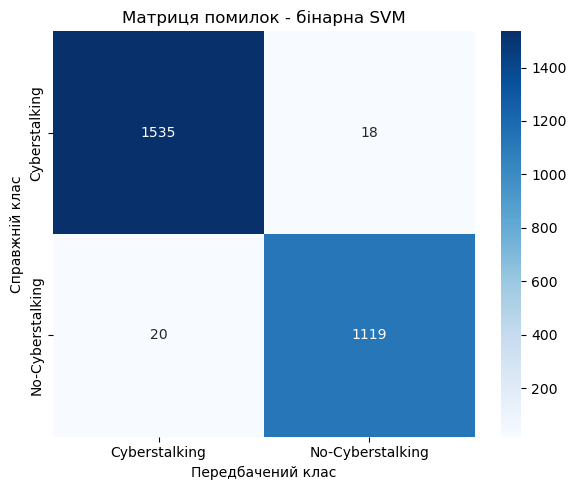

In [8]:
cm_bin = confusion_matrix(
    y_test_bin,
    y_pred_bin,
    labels=[0, 1]
)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_bin,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Cyberstalking", "No-Cyberstalking"],
    yticklabels=["Cyberstalking", "No-Cyberstalking"]
)
plt.xlabel("Передбачений клас")
plt.ylabel("Справжній клас")
plt.title("Матриця помилок - бінарна SVM")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "confusion_matrix_binary.png", dpi=150)
plt.show()

ROC-AUC для Cyberstalking: 0.9945


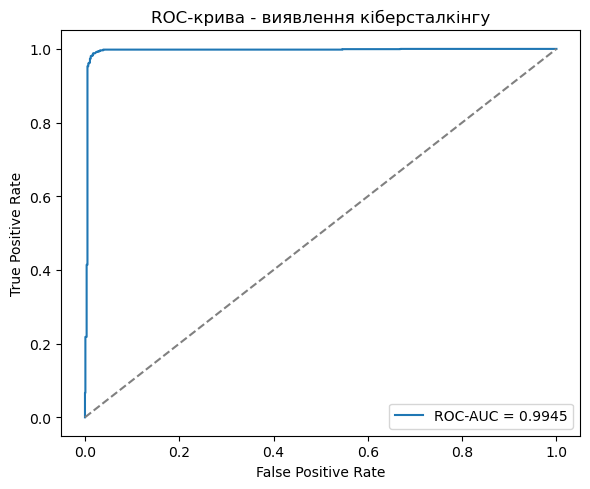

In [9]:
scores_cyber = -binary_model.decision_function(X_test_bin)
y_true_cyber = (y_test_bin == 0).astype(int)

roc_auc_bin = roc_auc_score(y_true_cyber, scores_cyber)
ap_bin = average_precision_score(y_true_cyber, scores_cyber)

print("ROC-AUC для Cyberstalking:", round(roc_auc_bin, 4))

fpr, tpr, _ = roc_curve(y_true_cyber, scores_cyber)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc_bin:.4f}")
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC-крива - виявлення кіберсталкінгу")
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "roc_curve_binary.png", dpi=150)
plt.show()

In [10]:
# навчальні дані для другої моделі
train_types = train_df[
    (train_df["y_binary"] == 0) &
    (train_df["Types"].isin(type_map))
].copy()

# тестові дані для незалежної оцінки другої моделі
test_types = test_df[
    (test_df["y_binary"] == 0) &
    (test_df["Types"].isin(type_map))
].copy()

train_types["y_type"] = train_types["Types"].map(type_map).astype(int)
test_types["y_type"] = test_types["Types"].map(type_map).astype(int)

print("Навчальні приклади для моделі типів:", len(train_types))
print("Тестові приклади для моделі типів:", len(test_types))

print("\nТипи у train:")
print(train_types["Types"].value_counts())

print("\nТипи у test:")
print(test_types["Types"].value_counts())

if train_types["y_type"].nunique() != 3:
    raise ValueError(
        "У навчальних даних другої моделі відсутній один із трьох типів."
    )

if test_types["y_type"].nunique() != 3:
    raise ValueError(
        "У тестовій вибірці відсутній один із трьох типів. "
        "Потрібно змінити групове розділення."
    )

Навчальні приклади для моделі типів: 6217
Тестові приклади для моделі типів: 1553

Типи у train:
Types
Intimidation        2310
Ordinary            2125
SexualHarassment    1782
Name: count, dtype: int64

Типи у test:
Types
Intimidation        575
Ordinary            539
SexualHarassment    439
Name: count, dtype: int64


In [11]:
type_grid = train_svm_pipeline(
    X_train=train_types["clean_text"],
    y_train=train_types["y_type"],
    groups_train=train_types["clean_text"].to_numpy(),
    name="Багатокласова SVM"
)
type_model = type_grid.best_estimator_

X_test_types = test_types["clean_text"]
y_test_types = test_types["y_type"]

y_pred_types = type_model.predict(X_test_types)
type_names = [
    "Intimidation",
    "Ordinary",
    "SexualHarassment"
]

print("\n=== Модель типів кіберсталкінгу: test ===")
print(classification_report(
    y_test_types,
    y_pred_types,
    labels=[0, 1, 2],
    target_names=type_names,
    digits=4,
    zero_division=0
))

print("Accuracy:",
      round(accuracy_score(y_test_types, y_pred_types), 4))

print("Macro-F1:",
      round(f1_score(y_test_types, y_pred_types,
                     average="macro", zero_division=0), 4))

Fitting 5 folds for each of 5 candidates, totalling 25 fits

Багатокласова SVM
Найкращі параметри: {'svm__C': 10}
Найкращий CV macro-F1: 0.8477

=== Модель типів кіберсталкінгу: test ===
                  precision    recall  f1-score   support

    Intimidation     0.9044    0.9217    0.9130       575
        Ordinary     0.8860    0.8794    0.8827       539
SexualHarassment     0.9190    0.9043    0.9116       439

        accuracy                         0.9021      1553
       macro avg     0.9031    0.9018    0.9024      1553
    weighted avg     0.9021    0.9021    0.9021      1553

Accuracy: 0.9021
Macro-F1: 0.9024


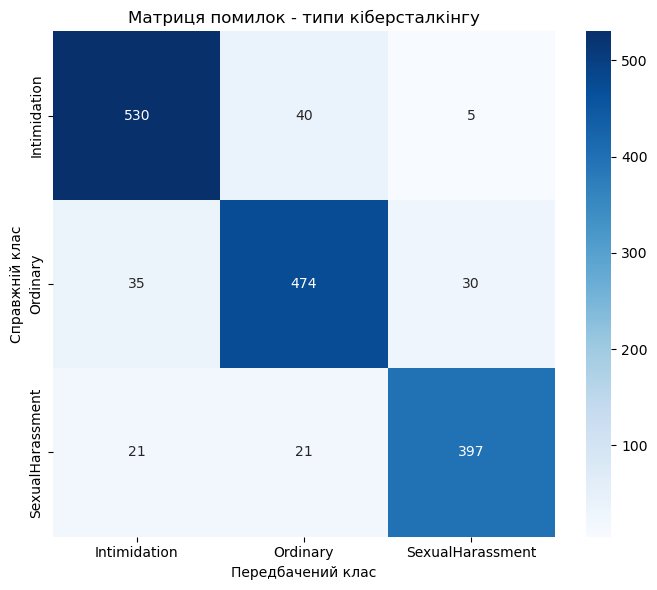

In [12]:
cm_types = confusion_matrix(
    y_test_types,
    y_pred_types,
    labels=[0, 1, 2]
)

plt.figure(figsize=(7, 6))
sns.heatmap(
    cm_types,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=type_names,
    yticklabels=type_names
)
plt.xlabel("Передбачений клас")
plt.ylabel("Справжній клас")
plt.title("Матриця помилок - типи кіберсталкінгу")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "confusion_matrix_types.png", dpi=150)
plt.show()

Macro ROC-AUC для типів: 0.9611


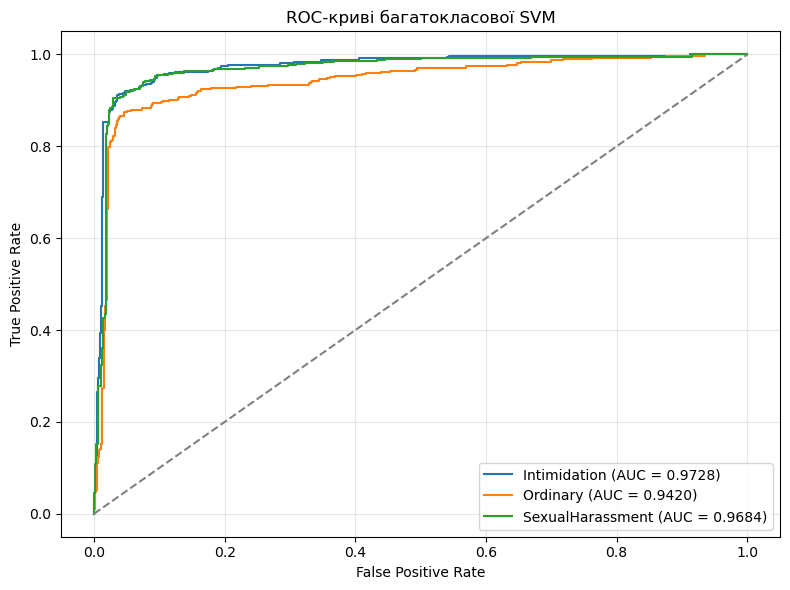

In [13]:
# перетворюємо мітки на формат one-vs-rest
y_test_types_bin = label_binarize(
    y_test_types,
    classes=[0, 1, 2]
)

type_scores = type_model.decision_function(X_test_types)
type_names = [
    "Intimidation",
    "Ordinary",
    "SexualHarassment"
]

plt.figure(figsize=(8, 6))
auc_values = []

for i, name in enumerate(type_names):
    fpr_i, tpr_i, _ = roc_curve(
        y_test_types_bin[:, i],
        type_scores[:, i]
    )

    auc_i = auc(fpr_i, tpr_i)
    auc_values.append(auc_i)

    plt.plot(
        fpr_i,
        tpr_i,
        label=f"{name} (AUC = {auc_i:.4f})"
    )

# макроусереднення AUC трьох класів
macro_auc_types = np.mean(auc_values)
print(
    "Macro ROC-AUC для типів:",
    round(macro_auc_types, 4)
)

plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC-криві багатокласової SVM")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "types_roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

Кількість повідомлень у наскрізному тесті: 2692

=== Повна оцінка системи ===
                  precision    recall  f1-score   support

No-Cyberstalking     0.9842    0.9824    0.9833      1139
    Intimidation     0.9031    0.9078    0.9055       575
        Ordinary     0.8632    0.8664    0.8648       539
SexualHarassment     0.9083    0.9021    0.9051       439

        accuracy                         0.9302      2692
       macro avg     0.9147    0.9147    0.9147      2692
    weighted avg     0.9303    0.9302    0.9302      2692

Accuracy: 0.9302
Macro-F1: 0.9147


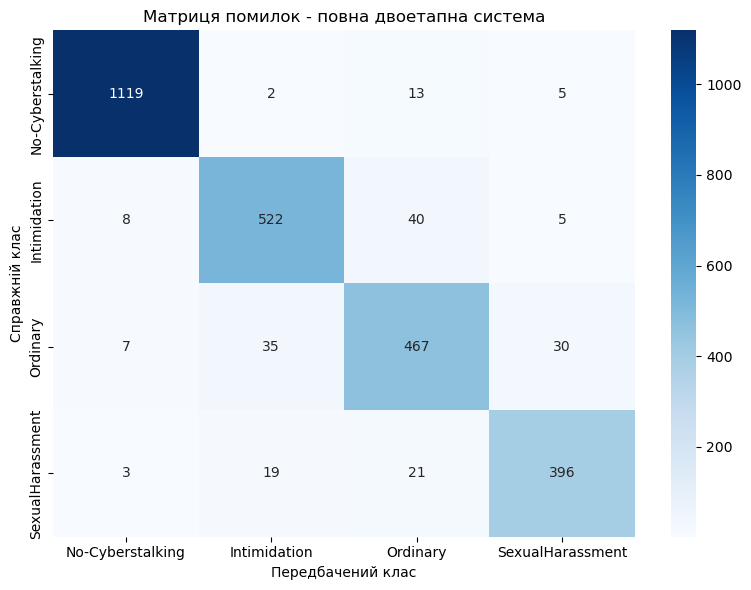

In [14]:
cascade_test = test_df[
    (test_df["y_binary"] == 1) |
    (
        (test_df["y_binary"] == 0) &
        (test_df["Types"].isin(type_map))
    )
].copy()

cascade_binary_pred = binary_model.predict(
    cascade_test["clean_text"]
)

# 0 = No-Cyberstalking
# 1 = Intimidation
# 2 = Ordinary
# 3 = SexualHarassment

true_final = []
pred_final = []

for i, (_, row) in enumerate(cascade_test.iterrows()):
    if row["y_binary"] == 1:
        true_final.append(0)
    else:
        true_final.append(1 + type_map[row["Types"]])

    if cascade_binary_pred[i] == 1:
        pred_final.append(0)
    else:
        # другий етап запускається тільки для повідомлень, які перша модель визначила як Cyberstalking
        predicted_type = type_model.predict(
            [row["clean_text"]]
        )[0]
        pred_final.append(1 + int(predicted_type))

final_names = [
    "No-Cyberstalking",
    "Intimidation",
    "Ordinary",
    "SexualHarassment"
]

print("Кількість повідомлень у наскрізному тесті:",
      len(cascade_test))

print("\n=== Повна оцінка системи ===")
print(classification_report(
    true_final,
    pred_final,
    labels=[0, 1, 2, 3],
    target_names=final_names,
    digits=4,
    zero_division=0
))

print("Accuracy:",
      round(accuracy_score(true_final, pred_final), 4))

print("Macro-F1:",
      round(f1_score(true_final, pred_final,
                     average="macro", zero_division=0), 4))

cm_final = confusion_matrix(
    true_final,
    pred_final,
    labels=[0, 1, 2, 3]
)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm_final,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=final_names,
    yticklabels=final_names
)
plt.xlabel("Передбачений клас")
plt.ylabel("Справжній клас")
plt.title("Матриця помилок - повна двоетапна система")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "confusion_matrix_cascade.png", dpi=150)
plt.show()

In [15]:
results = pd.DataFrame([
    {
        "Model": "Binary SVM",
        "Test size": len(test_df),
        "Accuracy": accuracy_score(y_test_bin, y_pred_bin),
        "Precision macro": precision_score(
            y_test_bin, y_pred_bin,
            average="macro", zero_division=0
        ),
        "Recall macro": recall_score(
            y_test_bin, y_pred_bin,
            average="macro", zero_division=0
        ),
        "F1 macro": f1_score(
            y_test_bin, y_pred_bin,
            average="macro", zero_division=0
        ),
        "ROC-AUC": roc_auc_bin
    },
    {
        "Model": "Types SVM",
        "Test size": len(test_types),
        "Accuracy": accuracy_score(y_test_types, y_pred_types),
        "Precision macro": precision_score(
            y_test_types, y_pred_types,
            average="macro", zero_division=0
        ),
        "Recall macro": recall_score(
            y_test_types, y_pred_types,
            average="macro", zero_division=0
        ),
        "F1 macro": f1_score(
            y_test_types, y_pred_types,
            average="macro", zero_division=0
        ),
        "ROC-AUC": macro_auc_types
    },
    {
        "Model": "Full cascade",
        "Test size": len(cascade_test),
        "Accuracy": accuracy_score(true_final, pred_final),
        "Precision macro": precision_score(
            true_final, pred_final,
            average="macro", zero_division=0
        ),
        "Recall macro": recall_score(
            true_final, pred_final,
            average="macro", zero_division=0
        ),
        "F1 macro": f1_score(
            true_final, pred_final,
            average="macro", zero_division=0
        ),
        "ROC-AUC": np.nan
    }
])

print(results.round(4).to_string(index=False))

results.to_csv(
    OUTPUT_DIR / "model_comparison.csv",
    index=False,
    encoding="utf-8-sig"
)

       Model  Test size  Accuracy  Precision macro  Recall macro  F1 macro  ROC-AUC
  Binary SVM       2692    0.9859           0.9857        0.9854    0.9855   0.9945
   Types SVM       1553    0.9021           0.9031        0.9018    0.9024   0.9611
Full cascade       2692    0.9302           0.9147        0.9147    0.9147      NaN


In [16]:
dump(
    binary_model,
    OUTPUT_DIR / "binary_svm_pipeline.joblib"
)

dump(
    type_model,
    OUTPUT_DIR / "type_svm_pipeline.joblib"
)
cv_results_binary = pd.DataFrame(binary_grid.cv_results_)
cv_results_types = pd.DataFrame(type_grid.cv_results_)

cv_results_binary.to_csv(
    OUTPUT_DIR / "cv_results_binary.csv",
    index=False,
    encoding="utf-8-sig"
)
cv_results_types.to_csv(
    OUTPUT_DIR / "cv_results_types.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Моделі та результати збережено в:", OUTPUT_DIR.resolve())

Моделі та результати збережено в: C:\Users\hp\cyberstalking_results


In [19]:
def evaluate_overfitting(model, X_train, y_train, X_test, y_test, name):
    pred_train = model.predict(X_train)
    pred_test = model.predict(X_test)

    train_acc = accuracy_score(y_train, pred_train)
    test_acc = accuracy_score(y_test, pred_test)

    train_f1 = f1_score(
        y_train, pred_train, average="macro", zero_division=0
    )
    test_f1 = f1_score(
        y_test, pred_test, average="macro", zero_division=0
    )

    return {
        "Model": name,
        "Train Accuracy": train_acc,
        "Test Accuracy": test_acc,
        "Train Macro-F1": train_f1,
        "Test Macro-F1": test_f1,
        "Accuracy Gap": train_acc - test_acc,
        "Macro-F1 Gap": train_f1 - test_f1
    }


# оцінювання бінарної моделі
binary_results = evaluate_overfitting(
    binary_model,
    X_train_bin,
    y_train_bin,
    X_test_bin,
    y_test_bin,
    "Binary SVM"
)

# щцінювання моделі типів кіберсталкінгу
types_results = evaluate_overfitting(
    type_model,
    train_types["clean_text"],
    train_types["y_type"],
    test_types["clean_text"],
    test_types["y_type"],
    "Types SVM"
)

# підсумкова таблиця
results_df = pd.DataFrame([binary_results, types_results])

print("Оцінювання перенавчання моделей")
display(results_df.round(4))

Оцінювання перенавчання моделей


,Model,Train Accuracy,Test Accuracy,Train Macro-F1,Test Macro-F1,Accuracy Gap,Macro-F1 Gap
0,Binary SVM,0.9995,0.9859,0.9995,0.9855,0.0137,0.0140
1,Types SVM,0.9855,0.9021,0.9858,0.9024,0.0834,0.0833
